# Neural Networks for Image Processing - Solution


**Business problem:** recognize a single scanned digit and decide what needs human review. MNIST is a benchmark,
not a representative sample of operational documents. One observation is one 28 x 28 grayscale image; the target is a digit 0-9.

In this notebook, we will:
1. Prepare image tensors without changing the official test boundary.
2. Compare a raw-pixel linear baseline with a small CNN.
3. Select a pipeline using validation cross-entropy, then evaluate fixed choices.
4. Interpret digit-level errors, review needs and limits of benchmark evidence.

**SW07 Lecture 3. Prerequisites:** neural-network training, classification and validation from Lectures 1 and 2.
One prepared-results activity fits the 10-minute lecture slot; the full sequence is a separate approximately 60-minute practical,
plus first-time downloads and model training. Do not count cold execution inside the lecture's 45 minutes.
The architecture uses two 3 x 3 convolutions (32/64 filters), pooling, dropout 0.5, Adam, batch 128 and five epochs.
Both models use final-epoch weights; validation chooses between pipelines, not between test results.


This is the completed companion to the [exercise](cnn_mnist_exercise.ipynb). Read the [concepts](cnn_mnist_concept.ipynb) first. Numbered steps, settings and code match the exercise. Try each interpretation before expanding its worked answer.

## Libraries and reproducibility

Install [the pinned TensorFlow environment](../requirements-cnn-mnist.txt) in a separate Python 3.9-3.11 environment:
`pip install -r ../requirements-cnn-mnist.txt` from this notebook's directory.
The kernel must use that environment. Package pins describe the tested stack, not every operating system.

Keras downloads the official `mnist.npz` archive on first use and caches it under `~/.keras/datasets/`.
A later run can use the cache without a dataset download. This is separate from the local Fashion-MNIST files used in Lecture 4.
The cell below fixes random seeds and requests deterministic TensorFlow operations; devices and versions can still affect results.

In [1]:
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, log_loss, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

SEED = 7
NUM_CLASSES = 10
BATCH_SIZE = 128
EPOCHS = 5
keras.utils.set_random_seed(SEED)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
print({name: importlib.metadata.version(name)
       for name in ['tensorflow', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']})

{'tensorflow': '2.15.1', 'numpy': '1.26.4', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.9.4'}


## 1. Prepare identical images and a validation split

Use the official 60,000-image training partition. Split it into 54,000 training and 6,000 validation images with stratification
and seed 7. The loader also returns the 10,000 official test images; keep them raw and unused until Step 5.
Set `pixel_scale` to the maximum value of an 8-bit pixel, so division maps pixel values to [0, 1].
This fixed transformation learns nothing from validation or test images.

The final axis is the single grayscale channel. Targets are one-hot vectors of length ten, matching categorical cross-entropy.
The image grid contains training examples, not examples selected for successful predictions.

    8192/11490434 [..............................] - ETA: 0s

   49152/11490434 [..............................] - ETA: 26s

   81920/11490434 [..............................] - ETA: 30s

  147456/11490434 [..............................] - ETA: 20s

  212992/11490434 [..............................] - ETA: 17s

...

 7766016/11490434 [===================>..........] - ETA: 0s

 7979008/11490434 [===================>..........] - ETA: 0s

10969088/11490434 [===========================>..] - ETA: 0s

11490434/11490434 [==============================] - 1s 0us/step


Training / validation / untouched official test: 54000 6000 10000
Input shape: (28, 28, 1) | target shape: (10,)


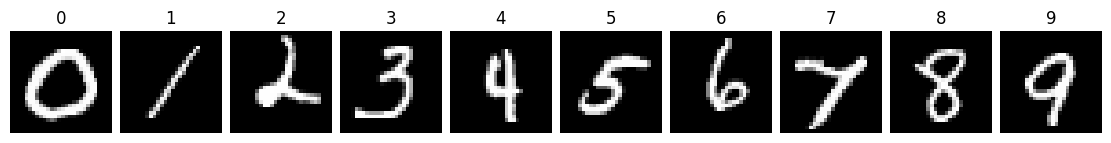

In [2]:
(raw_images, raw_labels), (raw_test_images, raw_test_labels) = keras.datasets.mnist.load_data()
training_indices, validation_indices = train_test_split(
    np.arange(len(raw_labels)), test_size=6000, stratify=raw_labels, random_state=SEED
)
pixel_scale = 255.0
train_images = raw_images[training_indices].astype('float32')[..., None] / pixel_scale
validation_images = raw_images[validation_indices].astype('float32')[..., None] / pixel_scale
train_labels = raw_labels[training_indices]
validation_labels = raw_labels[validation_indices]
train_targets = keras.utils.to_categorical(train_labels, NUM_CLASSES)
validation_targets = keras.utils.to_categorical(validation_labels, NUM_CLASSES)
assert not np.intersect1d(training_indices, validation_indices).size
print('Training / validation / untouched official test:', len(train_images), len(validation_images), len(raw_test_images))
print('Input shape:', train_images.shape[1:], '| target shape:', train_targets.shape[1:])
figure, axes = plt.subplots(1, 10, figsize=(11, 2), layout='constrained')
for digit, axis in enumerate(axes):
    position = np.flatnonzero(train_labels == digit)[0]
    axis.imshow(train_images[position, ..., 0], cmap='gray', vmin=0, vmax=1)
    axis.set_title(str(digit))
    axis.axis('off')
plt.show()

Why must the validation images remain outside fitting, even though division by 255 is fixed?

<details>
<summary>Answer and self-check</summary>

**Answer:** Validation estimates behavior on images not used to update weights. Fixed scaling does not remove the need for a held-out selection set. The official test partition is reserved for final evidence.

**Intermediate:** 3 points: no validation weight updates (1); validation selects pipelines (1); test remains separate (1).

**Common mistake:** Calling validation images training examples because the same normalization is applied.

</details>

## 2. Establish a business and statistical baseline

A training-majority rule always predicts the most frequent training digit. Its probability baseline uses training class proportions.
Do not assume exactly 10% accuracy: the ten digits are not perfectly balanced.
A second baseline is a trainable linear softmax model on the same 784 raw pixels. It tests whether convolutions add value.
Correct routing and reduced review workload are business outcomes; baseline accuracy is only a technical starting point.

In [3]:
prior_baseline = DummyClassifier(strategy='prior')
prior_baseline.fit(np.zeros((len(train_labels), 1)), train_labels)
prior_validation_probabilities = prior_baseline.predict_proba(np.zeros((len(validation_labels), 1)))
print('Training-majority digit:', int(prior_baseline.classes_[prior_baseline.class_prior_.argmax()]))
print('Prior validation accuracy:', accuracy_score(validation_labels, prior_validation_probabilities.argmax(axis=1)))
print('Prior validation log loss:', log_loss(validation_labels, prior_validation_probabilities, labels=np.arange(NUM_CLASSES)))

Training-majority digit: 1
Prior validation accuracy: 0.11233333333333333
Prior validation log loss: 2.301157024226629


What additional evidence does the trainable pixel baseline provide beyond guessing the training-majority digit?

<details>
<summary>Answer and self-check</summary>

**Answer:** It measures how well supervised linear combinations of the same image pixels can classify digits. CNN gains must be judged against that stronger baseline, with compute and error patterns considered as well.

**Intermediate:** 2 points: same pixel information and labels (1); stronger comparison than guessing, not equal compute (1).

**Common mistake:** Treating any improvement over roughly 10% accuracy as proof that a CNN is necessary.

</details>

## 3. Build the two pipelines

Set `kernel_size` to the height/width tuple for a 3 x 3 filter. Both convolutions use it with valid padding.
For the CNN, follow `28 -> 26 -> 13 -> 11 -> 5` in each spatial dimension. Flattening then gives 1,600 activations.
Convolutions learn shared local filters; ReLU introduces nonlinearity; pooling reduces resolution.
Dropout masks half the flattened activations in expectation during training and is inactive in ordinary prediction.

Both pipelines end with ten softmax probabilities. The CNN has 34,826 trainable parameters; the linear baseline has 7,850.
More parameters alone do not guarantee better generalization. The grid below is a benchmark image, not a complete document.

In [4]:
kernel_size = (3, 3)
linear_model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(NUM_CLASSES, activation='softmax'),
])
cnn_model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=kernel_size, activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=kernel_size, activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax'),
])
models = {'Linear softmax': linear_model, 'CNN': cnn_model}
print('Trainable parameters:', {name: model.count_params() for name, model in models.items()})
cnn_model.summary()

Trainable parameters: {'Linear softmax': 7850, 'CNN': 34826}
Model: "sequential_1"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 26, 26, 32)        320       


 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         


...

 dense_1 (Dense)             (None, 10)                16010     


Total params: 34826 (136.04 KB)


Trainable params: 34826 (136.04 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


What is shared across image positions, and which of the supplied layers have no trainable parameters?

<details>
<summary>Answer and self-check</summary>

**Answer:** Each convolution reuses its filter weights and biases at different positions. Pooling, flattening and dropout add no learned weights; convolutions and Dense do. Local responses are not causal explanations of a document decision.

**Intermediate:** 3 points: shared filter weights (1); nonparametric layers (1); no causal interpretation (1).

**Common mistake:** Assuming that flattening learns a representation or that dropout deletes units at prediction time.

</details>

## 4. Fit with a fixed budget and select on validation data

Set `loss_name` to the Keras categorical cross-entropy loss for one-hot targets and softmax outputs.
Both models use Adam's default learning rate (0.001), batch 128 and five epochs. No test images enter training or selection.
Use final-epoch weights, not a retrospectively chosen test-best checkpoint. Select the pipeline with the **lowest validation log loss**.

Training loss for the CNN is measured with dropout active, while validation uses inference mode.
A lower validation than training loss therefore does not by itself indicate leakage.
Accuracy measures correct class decisions; cross-entropy also evaluates the probability assigned to the true class.

Epoch 1/5


422/422 - 1s - loss: 0.7096 - accuracy: 0.8277 - val_loss: 0.4167 - val_accuracy: 0.8895 - 510ms/epoch - 1ms/step


Epoch 2/5


422/422 - 0s - loss: 0.3735 - accuracy: 0.9004 - val_loss: 0.3456 - val_accuracy: 0.9022 - 195ms/epoch - 463us/step


Epoch 3/5


...

422/422 - 10s - loss: 0.0688 - accuracy: 0.9784 - val_loss: 0.0461 - val_accuracy: 0.9868 - 10s/epoch - 24ms/step


Epoch 5/5


422/422 - 10s - loss: 0.0606 - accuracy: 0.9812 - val_loss: 0.0428 - val_accuracy: 0.9863 - 10s/epoch - 24ms/step


,Validation log loss,Validation accuracy
Linear softmax,0.2970,0.9132
CNN,0.0428,0.9863


Validation-selected model: CNN


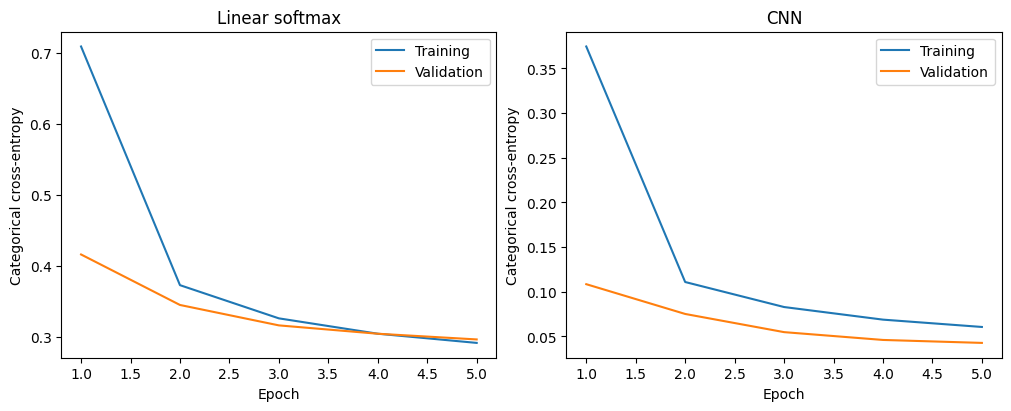

In [5]:
loss_name = 'categorical_crossentropy'
histories = {}
validation_rows = {}
for name, model in models.items():
    keras.utils.set_random_seed(SEED)
    model.compile(loss=loss_name, optimizer='adam', metrics=['accuracy'])
    histories[name] = model.fit(
        train_images, train_targets, batch_size=BATCH_SIZE, epochs=EPOCHS,
        validation_data=(validation_images, validation_targets), shuffle=True, verbose=2
    )
    measured = model.evaluate(validation_images, validation_targets, verbose=0)
    validation_rows[name] = {'Validation log loss': measured[0], 'Validation accuracy': measured[1]}
validation_results = pd.DataFrame.from_dict(validation_rows, orient='index')
selected_model = validation_results['Validation log loss'].idxmin()
display(validation_results.round(4))
print('Validation-selected model:', selected_model)
figure, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for axis, (name, history) in zip(axes, histories.items()):
    epoch_numbers = np.arange(1, len(history.history['loss']) + 1)
    axis.plot(epoch_numbers, history.history['loss'], label='Training')
    axis.plot(epoch_numbers, history.history['val_loss'], label='Validation')
    axis.set(title=name, xlabel='Epoch', ylabel='Categorical cross-entropy')
    axis.legend()
plt.show()

Which pipeline would you select under the declared rule? Why is five epochs not an equal-compute comparison?

<details>
<summary>Answer and self-check</summary>

**Answer:** Select the row with minimum validation log loss, even if the other row has slightly higher accuracy. A CNN performs more operations per example. Five epochs fixes data passes, not wall time, energy or total compute.

**Intermediate:** 3 points: use the observed validation minimum (1); distinguish accuracy from log loss (1); unequal compute (1).

**Common mistake:** Choosing a model from the test table or assuming more epochs must improve generalization.

</details>

## 5. Evaluate fixed choices on the official test partition

Now apply the same fixed pixel scaling to the official test images. Report accuracy and log loss for the prior rule and both models.
Keep the validation-selected pipeline regardless of test ranking. These are historical benchmark results, not a new deployment guarantee.
Do not use this test set to choose dropout, filters, epoch count or review thresholds.

In [6]:
test_images = raw_test_images.astype('float32')[..., None] / pixel_scale
test_targets = keras.utils.to_categorical(raw_test_labels, NUM_CLASSES)
test_probabilities = {'Training prior': prior_baseline.predict_proba(np.zeros((len(raw_test_labels), 1)))}
test_probabilities.update({name: model.predict(test_images, batch_size=256, verbose=0)
                           for name, model in models.items()})
test_predictions = {name: probabilities.argmax(axis=1) for name, probabilities in test_probabilities.items()}
test_results = pd.DataFrame.from_dict({name: {
    'Test accuracy': accuracy_score(raw_test_labels, test_predictions[name]),
    'Test log loss': log_loss(raw_test_labels, probabilities, labels=np.arange(NUM_CLASSES)),
} for name, probabilities in test_probabilities.items()}, orient='index')
display(test_results.round(4))
print('Validation-selected model, unchanged:', selected_model)

,Test accuracy,Test log loss
Training prior,0.1135,2.3010
Linear softmax,0.9210,0.2807
CNN,0.9884,0.0347


Validation-selected model, unchanged: CNN


How does the selected pipeline compare with both baselines? What should happen if the test ranking differs from validation?

<details>
<summary>Answer and self-check</summary>

**Answer:** Read both accuracy and log loss from the executed tables; calculate accuracy differences in percentage points. Keep the validation-selected choice. A rank reversal is uncertainty to investigate with new data, not permission to tune on this test.

**Intermediate:** 3 points: use measured results (1); percentage-point comparison (1); do not reselect on test (1).

**Common mistake:** Reporting a fabricated winning score or treating this historical comparison as independent confirmation after redesign.

</details>

## 6. Interpret errors and business consequences

Rows of the confusion matrix are true digits; columns are predicted digits. Inspect per-digit errors as well as overall accuracy.
The grid shows the first twelve test errors, or the first twelve test examples if there are none. This is explicit error inspection,
not a representative sample of all cases. Images show what happened, not why the model made a causal decision.

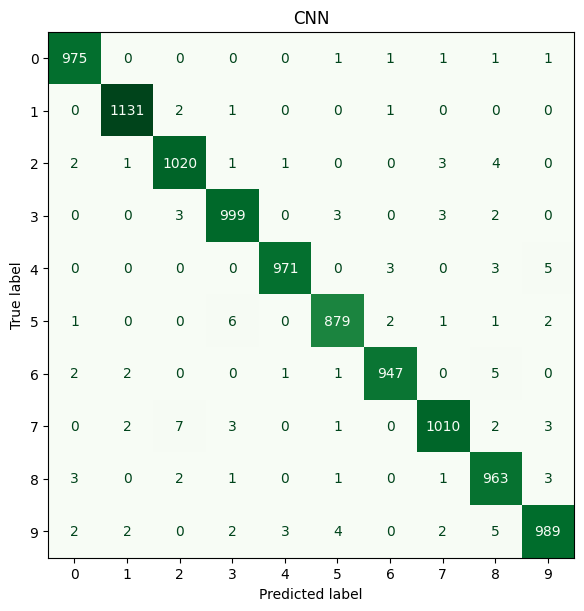

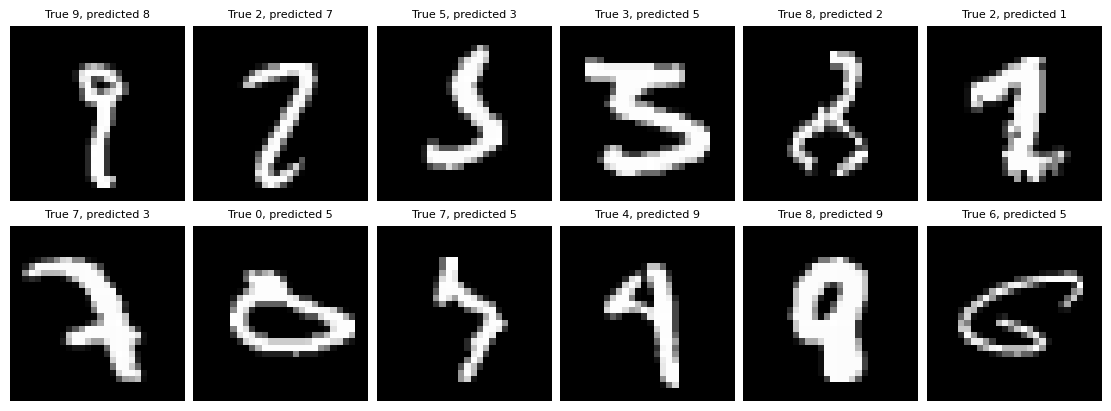

In [7]:
selected_predictions = test_predictions[selected_model]
figure, axis = plt.subplots(figsize=(7, 6), layout='constrained')
ConfusionMatrixDisplay.from_predictions(
    raw_test_labels, selected_predictions, labels=np.arange(NUM_CLASSES),
    values_format='d', colorbar=False, cmap='Greens', ax=axis
)
axis.set_title(selected_model)
plt.show()
error_positions = np.flatnonzero(selected_predictions != raw_test_labels)
positions = error_positions[:12] if len(error_positions) else np.arange(12)
figure, axes = plt.subplots(2, 6, figsize=(11, 4), layout='constrained')
for axis in axes.flat:
    axis.axis('off')
for axis, position in zip(axes.flat, positions):
    axis.imshow(raw_test_images[position], cmap='gray', vmin=0, vmax=255)
    axis.set_title(f'True {raw_test_labels[position]}, predicted {selected_predictions[position]}', fontsize=8)
plt.show()

Identify one observed digit confusion. Why could it matter more than another confusion in a document workflow?

<details>
<summary>Answer and self-check</summary>

**Answer:** Use an off-diagonal entry from the executed matrix, identify its true/predicted direction and connect it to a specified workflow cost. Equal accuracy can hide very different financial or review consequences. A digit benchmark alone supplies no monetary cost estimates.

**Intermediate:** 3 points: an actual off-diagonal observation (1); correct direction (1); explicit business assumption (1).

**Common mistake:** Claiming that the image grid explains which pixels caused a prediction or inventing financial savings.

</details>

## Business implications and limitations

MNIST digits are cropped, centered and grayscale; actual documents contain multiple characters, noise and changing capture devices.
This comparison uses one random seed and a fixed five-epoch budget. It does not optimize either architecture or isolate every source of gain.
Validation is development evidence. Repeated test inspection is not fresh confirmation.
Probability calibration, unfamiliar inputs, human review, latency, privacy and monitoring need separate evaluation.
Associations learned from pixels do not establish causal effects on business outcomes.

Would you automatically process documents with high maximum softmax probability? Specify the next evidence you need.

<details>
<summary>Answer and self-check</summary>

**Answer:** Not on this evidence alone. Evaluate representative documents under time-ordered or source-grouped separation, assess calibration and out-of-distribution failures, measure document-level error costs and review capacity, and retain a monitored human-review route.

**Intermediate:** 3 points: representative independent evidence (1); calibration and realistic costs (1); review/monitoring (1).

**Common mistake:** Treating softmax probability as a guaranteed correctness certificate.

</details>

## Summary and optional exercises

- Convolutions learn shared local patterns; flattening and a linear model provide a useful comparison.
- Train on training images, select on validation and evaluate fixed choices on the official test partition.
- Benchmark accuracy, trustworthy probabilities and business value are different claims.

**Optional practical:** predeclare one pooling or dropout change and compare using training/validation only.
**Further exercise:** test a controlled brightness or rotation shift on validation images. Do not treat this as a representative production shift.
Obtain fresh evaluation data before improving the system in response to historical test errors.

## References

**Required student reading:** James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023).
*An Introduction to Statistical Learning: With Applications in Python*. Springer. Neural-network material.
https://www.statlearning.com/

**Dataset:** LeCun, Y., Cortes, C., & Burges, C. J. C. *The MNIST Database of Handwritten Digits*.
https://yann.lecun.com/exdb/mnist/

**Official technical documentation:** [Keras MNIST](https://keras.io/api/datasets/mnist/),
[Conv2D](https://keras.io/api/layers/convolution_layers/convolution2d/),
[MaxPooling2D](https://keras.io/api/layers/pooling_layers/max_pooling2d/),
[Dropout](https://keras.io/api/layers/regularization_layers/dropout/).

**Optional reading:** Zhang, A., Lipton, Z. C., Li, M., & Smola, A. J.
*Dive into Deep Learning*. Convolutional neural networks. https://d2l.ai/

**Environment:** [Pinned CNN requirements](../requirements-cnn-mnist.txt).
Practical notebooks require TensorFlow; the small calculations here use NumPy, pandas and matplotlib.

### Jupyter notebook - footer info

Include this information when submitting your notebook.

In [8]:
import platform
from datetime import datetime

print(platform.platform())
print('Python:', platform.python_version())
print('Date:', datetime.now().isoformat(timespec='seconds'))

macOS-26.6.2-arm64-i386-64bit
Python: 3.11.11
Date: 2026-10-25T20:18:47
